# AML Dataset — Exploratory Data Analysis

This notebook explores the IBM AML dataset before modelling.
Key questions:
1. How imbalanced is the class distribution?
2. What do feature distributions look like?
3. Are there missing values?
4. How does transaction amount differ between fraud and legit?
5. Which banks / jurisdictions see the most activity?

Results are saved to `data/processed/eda_summary.json`.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as npr
import pandas as pd
import seaborn as sns

# Allow importing from src/
sys.path.insert(0, str(Path.cwd().parent / 'src'))

plt.rcParams['figure.figsize'] = (10, 4)
sns.set_theme(style='whitegrid')

Matplotlib is building the font cache; this may take a moment.


## Load Data

In [2]:
RAW_DIR = Path.cwd().parent / 'data' / 'raw'
PROCESSED_DIR = Path.cwd().parent / 'data' / 'processed'
IBM_FILENAME = 'HI-Small_Trans.csv'

IBM_COLUMNS = [
    'timestamp', 'from_bank', 'from_account', 'to_bank', 'to_account',
    'amount_received', 'receiving_currency', 'amount_paid',
    'payment_currency', 'payment_format', 'is_laundering'
]

raw_path = RAW_DIR / IBM_FILENAME
if not raw_path.exists():
    print(f'\n⚠️  Dataset not found at {raw_path}')
    print('Download HI-Small_Trans.csv from Kaggle and place it in data/raw/')
    print('Search: "IBM Transaction for Anti Money Laundering AML"')
    raise FileNotFoundError(f'{raw_path} not found')

df = pd.read_csv(raw_path, header=0)
df.columns = IBM_COLUMNS
print(f'Loaded {len(df):,} rows × {df.shape[1]} columns')
df.head()

Loaded 5,078,345 rows × 11 columns


,timestamp,from_bank,from_account,to_bank,to_account,amount_received,receiving_currency,amount_paid,payment_currency,payment_format,is_laundering
0,2022/09/01 00:20,10,8000EBD30,10,8000EBD30,3697.34,US Dollar,3697.34,US Dollar,Reinvestment,0
1,2022/09/01 00:20,3208,8000F4580,1,8000F5340,0.01,US Dollar,0.01,US Dollar,Cheque,0
2,2022/09/01 00:00,3209,8000F4670,3209,8000F4670,14675.57,US Dollar,14675.57,US Dollar,Reinvestment,0
3,2022/09/01 00:02,12,8000F5030,12,8000F5030,2806.97,US Dollar,2806.97,US Dollar,Reinvestment,0
4,2022/09/01 00:06,10,8000F5200,10,8000F5200,36682.97,US Dollar,36682.97,US Dollar,Reinvestment,0


## 1. Class Imbalance

Legit transactions: 5,073,168
Fraud transactions: 5,177
Fraud rate: 0.1%


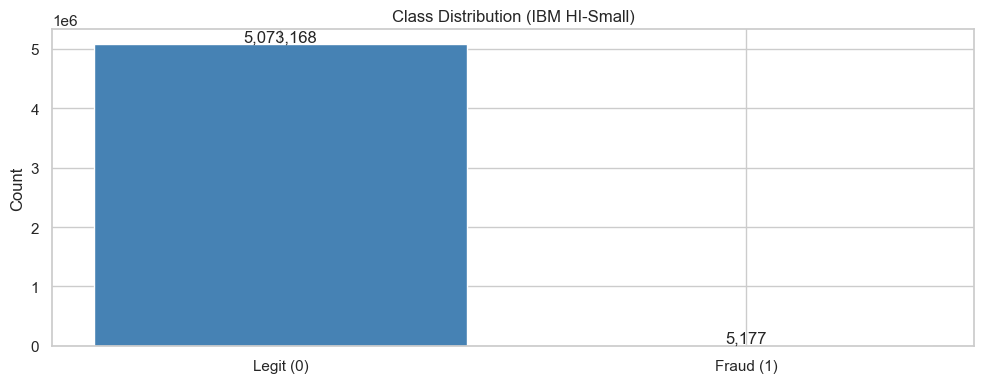

In [3]:
class_counts = df['is_laundering'].value_counts()
fraud_rate = df['is_laundering'].mean()

print(f'Legit transactions: {class_counts[0]:,}')
print(f'Fraud transactions: {class_counts[1]:,}')
print(f'Fraud rate: {fraud_rate:.1%}')

fig, ax = plt.subplots()
bars = ax.bar(['Legit (0)', 'Fraud (1)'], class_counts.values,
              color=['steelblue', 'salmon'])
for bar, val in zip(bars, class_counts.values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 100,
            f'{val:,}', ha='center', va='bottom')
ax.set_title('Class Distribution (IBM HI-Small)')
ax.set_ylabel('Count')
plt.tight_layout()
plt.show()

## 2. Feature Distributions

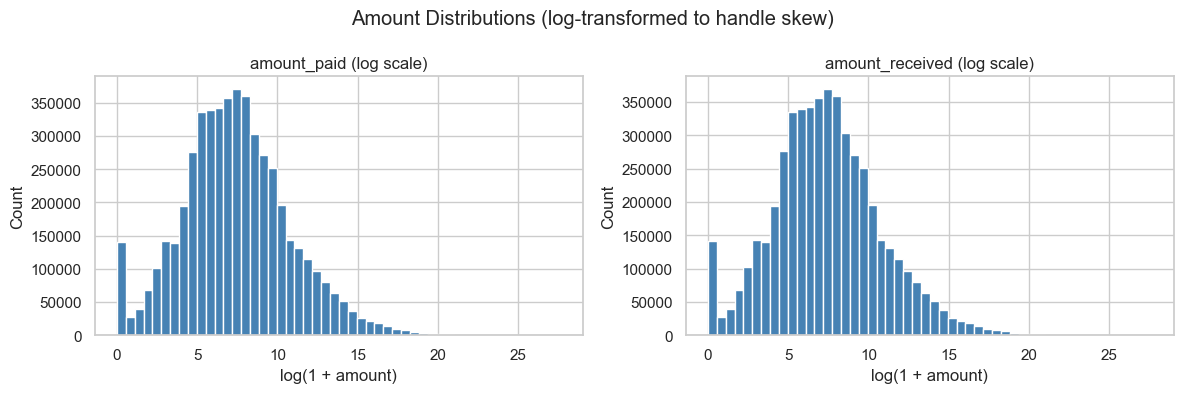

Payment format distribution:
payment_format
Cheque          1864331
Credit Card     1323324
ACH              600797
Cash             490891
Reinvestment     481056
Wire             171855
Bitcoin          146091
Name: count, dtype: int64


In [9]:
numeric_cols = ['amount_paid', 'amount_received']

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col in zip(axes, numeric_cols):
    ax.hist(npr.log1p(df[col]), bins=50, color='steelblue', edgecolor='white')
    ax.set_title(f'{col} (log scale)')
    ax.set_xlabel('log(1 + amount)')
    ax.set_ylabel('Count')
plt.suptitle('Amount Distributions (log-transformed to handle skew)')
plt.tight_layout()
plt.show()

print('Payment format distribution:')
print(df['payment_format'].value_counts())

## 3. Missing Values

In [5]:
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)
missing_df = pd.DataFrame({'missing_count': missing, 'missing_pct': missing_pct})
print(missing_df)
print(f'\nTotal missing values: {missing.sum()}')

                    missing_count  missing_pct
timestamp                       0          0.0
from_bank                       0          0.0
from_account                    0          0.0
to_bank                         0          0.0
to_account                      0          0.0
amount_received                 0          0.0
receiving_currency              0          0.0
amount_paid                     0          0.0
payment_currency                0          0.0
payment_format                  0          0.0
is_laundering                   0          0.0

Total missing values: 0


## 4. Transaction Amount by Label

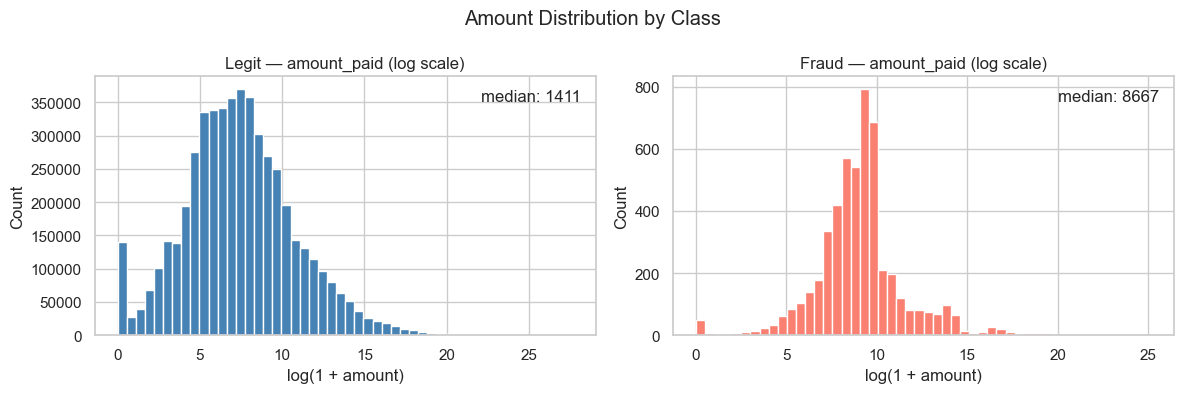

Amount stats by class:
                   count          mean           std       min      25%  \
is_laundering                                                             
0              5073168.0  4.477000e+06  8.688463e+08  0.000001   184.16   
1                 5177.0  3.613531e+07  1.527919e+09  0.003227  2634.97   

                   50%       75%           max  
is_laundering                                   
0              1410.99  12279.34  1.046302e+12  
1              8667.21  18832.27  8.485314e+10  


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, label, color, name in zip(
    axes, [0, 1], ['steelblue', 'salmon'], ['Legit', 'Fraud']
):
    subset = df[df['is_laundering'] == label]['amount_paid']
    ax.hist(npr.log1p(subset), bins=50, color=color, edgecolor='white')
    ax.set_title(f'{name} — amount_paid (log scale)')
    ax.set_xlabel('log(1 + amount)')
    ax.set_ylabel('Count')
    ax.text(0.97, 0.95, f'median: {subset.median():.0f}',
            transform=ax.transAxes, ha='right', va='top')

plt.suptitle('Amount Distribution by Class')
plt.tight_layout()
plt.show()

print('Amount stats by class:')
print(df.groupby('is_laundering')['amount_paid'].describe())

## 5. Bank / Jurisdiction Activity

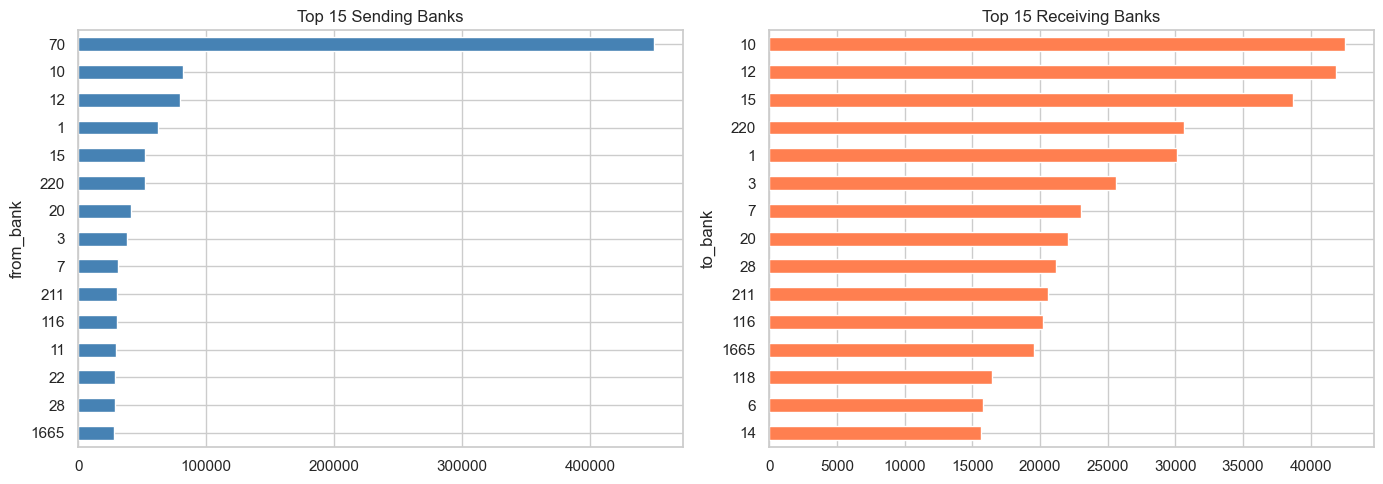


Fraud rate by payment format:
                fraud_rate    count
payment_format                     
ACH               0.007462   600797
Bitcoin           0.000383   146091
Cash              0.000220   490891
Cheque            0.000174  1864331
Credit Card       0.000156  1323324
Reinvestment      0.000000   481056
Wire              0.000000   171855


In [7]:
top_from_banks = df['from_bank'].value_counts().head(15)
top_to_banks = df['to_bank'].value_counts().head(15)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
top_from_banks.plot(kind='barh', ax=axes[0], color='steelblue')
axes[0].set_title('Top 15 Sending Banks')
axes[0].invert_yaxis()

top_to_banks.plot(kind='barh', ax=axes[1], color='coral')
axes[1].set_title('Top 15 Receiving Banks')
axes[1].invert_yaxis()

plt.tight_layout()
plt.show()

# Fraud rate per payment format
fraud_by_format = df.groupby('payment_format')['is_laundering'].agg(['mean', 'count'])
fraud_by_format.columns = ['fraud_rate', 'count']
fraud_by_format = fraud_by_format.sort_values('fraud_rate', ascending=False)
print('\nFraud rate by payment format:')
print(fraud_by_format)

## Save EDA Summary

In [8]:
eda_summary = {
    "total_rows": int(len(df)),
    "total_columns": int(df.shape[1]),
    "fraud_count": int(class_counts.get(1, 0)),
    "legit_count": int(class_counts.get(0, 0)),
    "fraud_rate": float(fraud_rate),
    "missing_values_total": int(missing.sum()),
    "missing_by_column": missing[missing > 0].to_dict(),
    "amount_paid_stats": {
        "fraud": df[df['is_laundering'] == 1]['amount_paid'].describe().to_dict(),
        "legit": df[df['is_laundering'] == 0]['amount_paid'].describe().to_dict(),
    },
    "payment_format_counts": df['payment_format'].value_counts().to_dict(),
    "fraud_rate_by_payment_format": fraud_by_format['fraud_rate'].to_dict(),
    "unique_from_banks": int(df['from_bank'].nunique()),
    "unique_to_banks": int(df['to_bank'].nunique()),
}

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
out_path = PROCESSED_DIR / 'eda_summary.json'
with open(out_path, 'w') as f:
    json.dump(eda_summary, f, indent=2, default=str)

print(f'EDA summary saved to {out_path}')
print(json.dumps({k: v for k, v in eda_summary.items() if not isinstance(v, dict)}, indent=2))

EDA summary saved to /Users/leofont/Documents/src/leofont.com/aml_ai/aml-demo/data/processed/eda_summary.json
{
  "total_rows": 5078345,
  "total_columns": 11,
  "fraud_count": 5177,
  "legit_count": 5073168,
  "fraud_rate": 0.0010194266045335635,
  "missing_values_total": 0,
  "unique_from_banks": 30470,
  "unique_to_banks": 15811
}
